Shape: (303, 14)

Column types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing values in raw data:
ca      4
thal    2
dtype: int64

Missing values in cleaned data: 0

Summary statistics:
          count        mean        std    min    25%    50%    75%    max
age       303.0   54.438944   9.038662   29.0   48.0   56.0   61.0   77.0
sex       303.0    0.679868   0.467299    0.0    0.0    1.0    1.0    1.0
cp        303.0    3.158416   0.960126    1.0    3.0    3.0    4.0    4.0
trestbps  303.0  131.689769  17.599748   94.0  120.0  130.0  140.0  200.0
chol      303.0  246.693069  51.776918  126.0  211.0  241.0  275.0  564.0
fbs       303.0    0.148515   0.356198    0.0    0.0    0.0    0.0    1.0
restecg   303.0    0.990099   0.994971

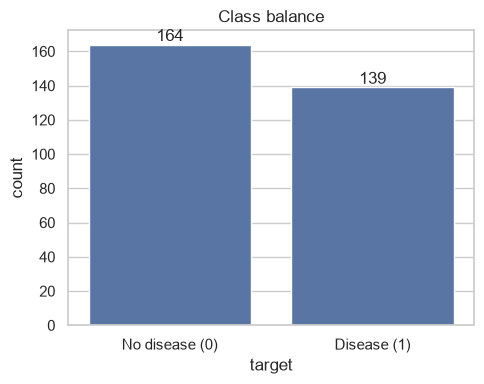


Class balance (%):
target
0    54.1
1    45.9
Name: count, dtype: float64


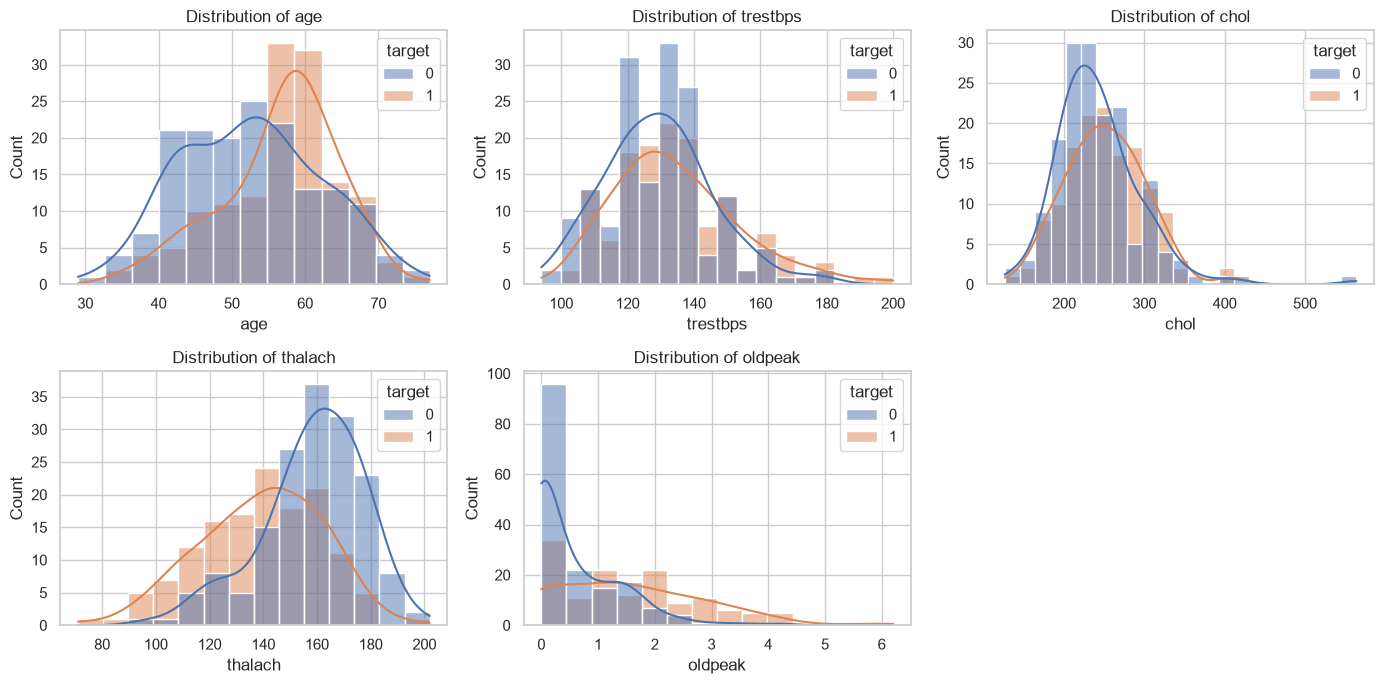

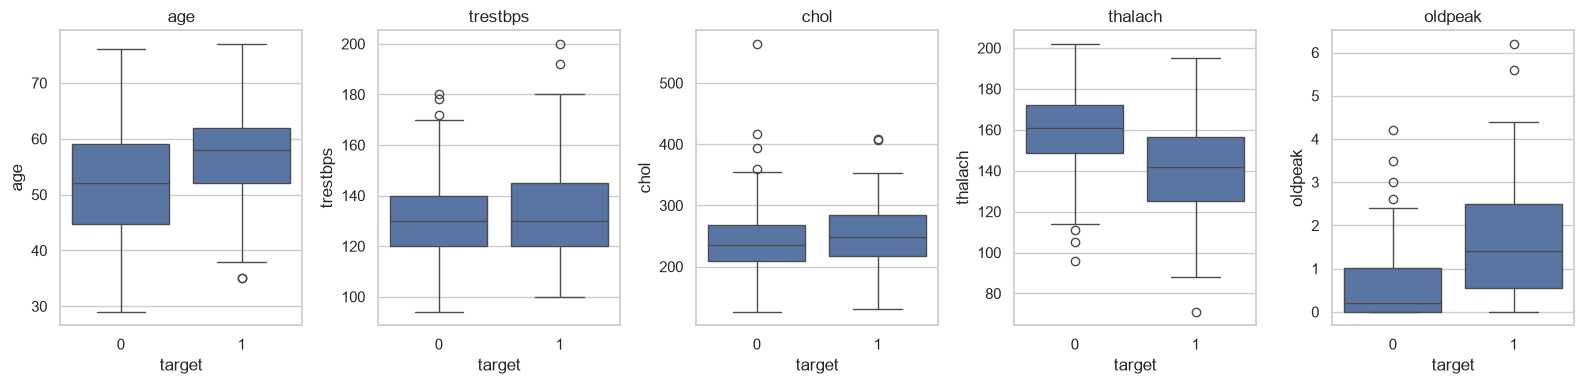

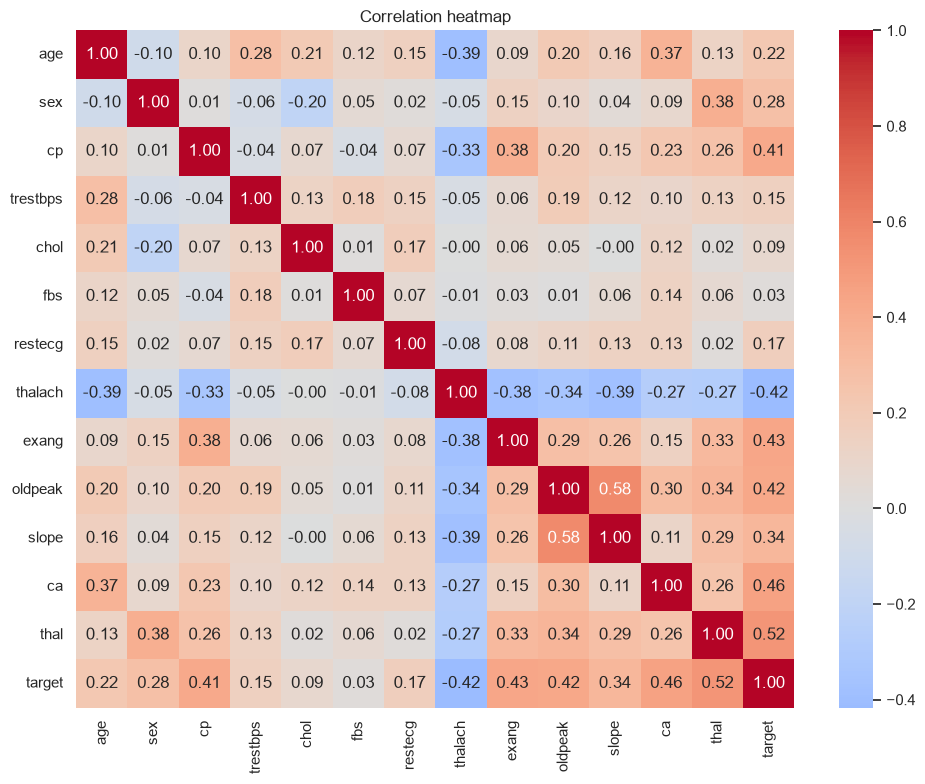


Correlation with target:
thal        0.522057
ca          0.460033
exang       0.431894
oldpeak     0.424510
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
thalach    -0.417167
Name: target, dtype: float64


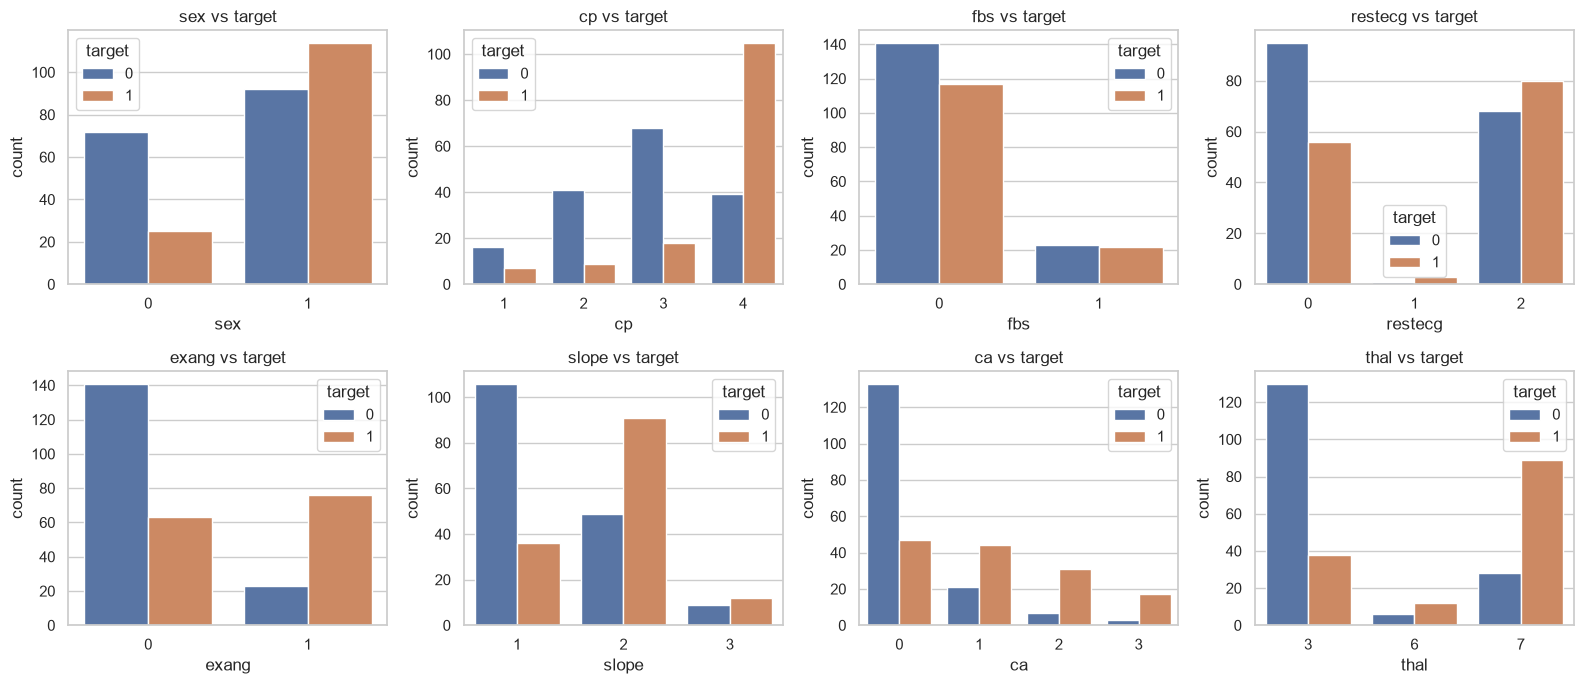


All plots saved to C:\Users\rohin\-heart-disease-mlops\screenshots\eda


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

plot_dir = Path("../screenshots/eda")
plot_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/processed/heart_clean.csv")
raw = pd.read_csv("../data/raw/heart.csv")

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# ---------- 1. Structure, summary stats, missing values ----------
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values in raw data:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nMissing values in cleaned data:", df.isna().sum().sum())
print("\nSummary statistics:")
print(df.describe().T)

# ---------- 2. Class balance ----------
counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="target")
ax.set_xticks([0, 1])
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Class balance")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(plot_dir / "class_balance.png", dpi=150)
plt.show()

print("\nClass balance (%):")
print((counts / len(df) * 100).round(1))

# ---------- 3. Histograms ----------
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(plot_dir / "histograms.png", dpi=150)
plt.show()

# ---------- 4. Boxplots (outliers) ----------
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x="target", y=col, ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.savefig(plot_dir / "boxplots.png", dpi=150)
plt.show()

# ---------- 5. Correlation heatmap ----------
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(plot_dir / "correlation_heatmap.png", dpi=150)
plt.show()

print("\nCorrelation with target:")
print(df.corr()["target"].drop("target").sort_values(ascending=False))

# ---------- 6. Categorical features vs target ----------
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue="target", ax=axes[i])
    axes[i].set_title(f"{col} vs target")
plt.tight_layout()
plt.savefig(plot_dir / "categorical_vs_target.png", dpi=150)
plt.show()

print("\nAll plots saved to", plot_dir.resolve())